# Лабораторная работа №3: оптимизация гиперпараметров
## 1. Данные и разбиение

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)

X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, " test:", X_test.shape)
print("доля выживших: train", round(y_train.mean(), 3), " test", round(y_test.mean(), 3))

train: (712, 11)  test: (179, 11)
доля выживших: train 0.383  test 0.385


### Вывод по данным и разбиению

Беру задачу из ЛР2: по данным о пассажире Titanic предсказать, выжил ли он. Метрика, как в ЛР2, — F1, потому что классы несбалансированы (выжили 38%).

Разбиение такое же, как в ЛР2: 80% пассажиров в train и 20% в test, `random_state` = 42. 

Test откладываю до финальной проверки: все гиперпараметры подбираю только по F1 на кросс-валидации на train.

## 2. Подготовка признаков

In [2]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer


def extract_title(name):
    title = name.split(",")[1].split(".")[0].strip()
    title = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}.get(title, title)
    return title if title in ["Mr", "Mrs", "Miss", "Master"] else "Rare"


NUM_FEATURES = ["Pclass", "Age", "AgeMissing", "SibSp", "Parch",
                "FamilySize", "IsAlone", "HasCabin", "LogFare"]
CAT_FEATURES = ["Sex", "Embarked", "Title"]


class TitanicFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        titles = X["Name"].map(extract_title)
        self.age_by_title_ = X["Age"].groupby(titles).median()
        self.age_global_ = X["Age"].median()
        return self

    def transform(self, X):
        d = X.copy()
        d["Title"] = d["Name"].map(extract_title)
        d["AgeMissing"] = d["Age"].isna().astype(int)
        d["Age"] = d["Age"].fillna(d["Title"].map(self.age_by_title_)).fillna(self.age_global_)
        d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
        d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
        d["HasCabin"] = d["Cabin"].notna().astype(int)
        d["LogFare"] = np.log1p(d["Fare"])
        return d[NUM_FEATURES + CAT_FEATURES]


def make_pipeline(model):
    cat_step = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    prep = ColumnTransformer([
        ("num", "passthrough", NUM_FEATURES),
        ("cat", cat_step, CAT_FEATURES),
    ])
    return Pipeline([("features", TitanicFeatures()), ("prep", prep), ("model", model)])


make_pipeline(None).named_steps["features"].fit_transform(X_train).head()

,Pclass,Age,AgeMissing,SibSp,Parch,FamilySize,IsAlone,HasCabin,LogFare,Sex,Embarked,Title
692,3,30.0,1,0,0,1,1,0,4.051712,male,S,Mr
481,2,30.0,1,0,0,1,1,0,0.000000,male,S,Mr
527,1,30.0,1,0,0,1,1,1,5.406181,male,S,Mr
855,3,18.0,0,0,1,2,0,0,2.336987,female,S,Mrs
801,2,31.0,0,1,1,3,0,0,3.305054,female,S,Mrs


### Вывод по подготовке признаков

Признаки те же, что в ЛР2, чтобы F1 было сравнимо с прошлой работой. Все преобразования находятся внутри pipeline, поэтому при кросс-валидации они обучаются только на обучающей части каждого fold, и информация из проверочной части не попадает в обучение.

## 3. Кросс-валидация

In [3]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for i, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    y_val = y_train.iloc[val_idx]
    print(f"fold {i}: обучение {len(tr_idx)}, проверка {len(val_idx)}, "
          f"выживших в проверке {y_val.sum()} ({y_val.mean():.2f})")

fold 1: обучение 569, проверка 143, выживших в проверке 55 (0.38)
fold 2: обучение 569, проверка 143, выживших в проверке 55 (0.38)
fold 3: обучение 570, проверка 142, выживших в проверке 55 (0.39)
fold 4: обучение 570, проверка 142, выживших в проверке 54 (0.38)
fold 5: обучение 570, проверка 142, выживших в проверке 54 (0.38)


### Вывод по кросс-валидации

Использую `StratifiedKFold` с 5 folds. В каждом fold модель обучается на 570 пассажирах и проверяется на 142 пассажирах. Стратификация сохраняет долю выживших 0.38 в каждом fold.

**Почему 5 folds.** В train всего 712 пассажиров. При 10 folds в проверочной части было бы около 71 человек и только ~27 выживших: одна-две ошибки сильно меняли бы F1, и оценка на каждом fold была бы шумной. При 3 folds модель обучалась бы только на 2/3  данных, то есть заметно меньше, чем финальная модель. 5 folds — компромисс: в проверке ~55 выживших, обучение на 80% train, и всего 5 обучений на каждую комбинацию параметров.

**Зачем нужна кросс-валидация.** Она оценивает, как модель работает на новых данных, не используя test. Каждый пассажир из train ровно один раз попадает в проверочную часть, поэтому оценка использует пассажиров, которых не видела при обучении. Кроме среднего, видно различия между folds, то есть насколько результат устойчив.

**Почему одного разбиения train/test недостаточно.** Test маленький (179 пассажиров, ~69 выживших). Результат на нём сильно зависит от того, какие пассажиры туда попали: на другом разбиении лучшими могли бы оказаться другие параметры. При кросс-валидации результат усредняется по 5 разным проверочным частям, и случайность меньше влияет на выбор.

**Что будет, если выбирать гиперпараметры по test.** Если много раз проверять разные параметры на test и брать лучшие, параметры подстроятся под конкретных пассажиров из test. Test тогда фактически станет частью обучения, и оценка на нём будет завышенной: на новых пассажирах модель окажется хуже. Поэтому test использую только один раз, для финальной проверки уже выбранной модели.

## 4. Baseline

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

baseline = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))

params = baseline.named_steps["model"].get_params()
print({k: params[k] for k in ["criterion", "max_depth", "min_samples_leaf", "min_samples_split", "max_features"]})

cv_base = cross_validate(baseline, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
print("F1 по folds:", cv_base["test_score"].round(3))
print(f"CV F1 = {cv_base['test_score'].mean():.3f} ± {cv_base['test_score'].std():.3f}")
print(f"F1 на обучающих частях = {cv_base['train_score'].mean():.3f}")

{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'max_features': None}
F1 по folds: [0.739 0.661 0.705 0.703 0.724]
CV F1 = 0.706 ± 0.026
F1 на обучающих частях = 0.985


### Вывод по baseline

Baseline — дерево решений с параметрами по умолчанию: `criterion` = gini, `max_depth` = None (глубина не ограничена), `min_samples_leaf` = 1, `min_samples_split` = 2, `max_features` = None (в каждом разбиении рассматриваются все признаки). Это значит, что дерево растёт, пока в каждом листе не останутся пассажиры только одного класса.

CV F1 = 0.706 ± 0.026. По отдельным folds F1 меняется от 0.661 до 0.739, то есть разница между лучшим и худшим fold почти 0.08. Если бы я оценивала модель по одному разбиению, результат мог бы оказаться любым из этого диапазона.

На обучающих частях F1 = 0.985, а на проверочных 0.706: разрыв 0.279. Дерево запоминает пассажиров из обучения, а на новых работает заметно хуже — это переобучение. В ЛР2 на test у этой модели было F1 = 0,725, это попадает в диапазон значений по folds.

Задача подбора гиперпараметров — ограничить сложность дерева так, чтобы CV F1 стал лучше baseline (0.706).

## 5. Гиперпараметры

Выбираю три гиперпараметра дерева. Первые два ограничивают его сложность, третий определяет, как выбираются разбиения.

**`max_depth`** — максимальная глубина дерева, то есть сколько вопросов подряд дерево может задать пассажиру.
- Диапазон: от 1 до 10 и `None` (без ограничения). В baseline дерево выросло до глубины 23, но на ~570 пассажирах после глубины 10 оно уже почти полностью запоминает данные.
- Ожидание: при малой глубине (1–2) модель слишком простая и не успевает учесть даже класс и возраст — это недообучение. С ростом глубины CV F1 сначала растёт, а потом падает, потому что дерево начинает запоминать отдельных пассажиров — это переобучение.

**`min_samples_leaf`** — минимальное число пассажиров в листе. Разбиение не делается, если в одной из частей останется меньше пассажиров.
- Диапазон: от 1 до 40. Значение 1 означает, что лист может содержать одного пассажира.
- Ожидание: при маленьких значениях дерево делает листья под отдельных людей — переобучение. При слишком больших (40 — это ~7% обучающей части) листья становятся крупными, и дерево не может выделить небольшие группы, например мальчиков с титулом Master, — недообучение.

**`criterion`** — функция, по которой дерево оценивает, насколько «чистыми» получаются части после разбиения: `gini` (индекс Джини) или `entropy` (энтропия). Обе равны 0, если в узле пассажиры одного класса, и максимальны при соотношении 50 на 50.
- Значения: `gini`, `entropy`.
- Ожидание: обе функции почти одинаково ранжируют разбиения, поэтому влияние, скорее всего, будет слабым. Этот параметр проверяю, чтобы убедиться, что не все гиперпараметры одинаково важны.

## 6. Grid Search

In [5]:
import time
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_depth": [1, 2, 3, 4, 5, 6, 7, 8, 10, None],
    "model__min_samples_leaf": [1, 2, 5, 10, 20, 40],
    "model__criterion": ["gini", "entropy"],
}

grid = GridSearchCV(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_grid, cv=cv, scoring="f1", n_jobs=-1, return_train_score=True
)

start = time.perf_counter()
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - start

print("комбинаций:", len(grid.cv_results_["params"]))
print(f"время: {grid_time:.2f} с")
print("лучшие параметры:", grid.best_params_)
print(f"CV F1 = {grid.best_score_:.3f} ± {grid.cv_results_['std_test_score'][grid.best_index_]:.3f}")

комбинаций: 120
время: 14.06 с
лучшие параметры: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1}
CV F1 = 0.762 ± 0.047


### Вывод по Grid Search

**Пространство поиска:** `max_depth` ∈ {1, 2, 3, 4, 5, 6, 7, 8, 10, None}, `min_samples_leaf` ∈ {1, 2, 5, 10, 20, 40}, `criterion` ∈ {gini, entropy}. Grid Search перебирает все сочетания: 10 × 6 × 2 = 120 комбинаций. Каждая проверяется на 5 folds, всего 600 обучений. Поиск занял 14.06 с.

**Лучшие параметры:** `max_depth` = 3, `min_samples_leaf` = 1, `criterion` = gini. CV F1 = 0.762 ± 0.047, это на 0.056 выше baseline (0,706).

Лучшим оказалось неглубокое дерево: при глубине 3 у него не больше 8 листьев, то есть оно может задать пассажиру не больше 3 вопросов подряд. Этого достаточно, чтобы учесть самые важные признаки (титул, класс, цену билета), но мало, чтобы запомнить отдельных пассажиров, как это делало дерево без ограничений.

`min_samples_leaf` = 1 при такой глубине почти не ограничивает дерево: глубина 3 сама по себе уже не даёт сделать много маленьких листьев. Значит, главное ограничение здесь — max_depth.

## 7. Random Search

In [6]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    "model__max_depth": randint(1, 21),
    "model__min_samples_leaf": randint(1, 61),
    "model__criterion": ["gini", "entropy"],
}

rand = RandomizedSearchCV(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_dist, n_iter=120, cv=cv, scoring="f1", n_jobs=-1,
    random_state=RANDOM_STATE, return_train_score=True
)

start = time.perf_counter()
rand.fit(X_train, y_train)
rand_time = time.perf_counter() - start

params_list = rand.cv_results_["params"]
print("комбинаций:", len(params_list), " из них разных:", len({tuple(sorted(p.items())) for p in params_list}))
print(f"время: {rand_time:.2f} с")
print("лучшие параметры:", rand.best_params_)
print(f"CV F1 = {rand.best_score_:.3f} ± {rand.cv_results_['std_test_score'][rand.best_index_]:.3f}")

комбинаций: 120  из них разных: 120
время: 14.29 с
лучшие параметры: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1}
CV F1 = 0.762 ± 0.047


In [7]:
compare = pd.DataFrame({
    "комбинаций проверено": [len(grid.cv_results_["params"]), len(params_list)],
    "размер пространства": [120, 20 * 60 * 2],
    "время, с": [grid_time, rand_time],
    "CV F1": [grid.best_score_, rand.best_score_],
}, index=["Grid Search", "Random Search"]).round(3)
compare

,комбинаций проверено,размер пространства,"время, с",CV F1
Grid Search,120,120,14.063,0.762
Random Search,120,2400,14.293,0.762


### Вывод по Random Search

**Пространство поиска:** `max_depth` — любое целое от 1 до 20, `min_samples_leaf` — от 1 до 60, `criterion` ∈ {gini, entropy}. Всего 2400 комбинаций, перебрать их сеткой было бы в 20 раз дороже. Случайно проверено 120 комбинаций (столько же, сколько в Grid Search), все разные. Это 5% пространства.

**Сравнение с Grid Search:**
- **качество:** Random Search нашёл те же параметры и тот же CV F1 = 0.762 ± 0.047;
- **число комбинаций:** одинаковое, 120, но Grid Search проверил всё своё пространство, а Random Search — только 5% более широкого;
- **время:** почти одинаковое (14.06 с и 14.29 с), потому что число обучений одинаковое. Время зависит от числа обучений (количество комбинаций х folds), а не от размера пространства.

**Когда случайный поиск лучше полного перебора.** Число комбинаций в сетке растёт как произведение числа значений каждого параметра: добавить ещё один параметр с 10 значениями значит увеличить перебор в 10 раз. Random Search проверяет фиксированное число комбинаций, сколько бы ни было параметров и значений.

Кроме того, обычно важны только некоторые параметры. Если в сетке 10 значений важного параметра и 10 неважного, то из 100 комбинаций Grid Search проверит только 10 разных значений важного. Random Search при тех же 100 комбинациях проверит почти 100 разных значений важного параметра. Поэтому случайный поиск предпочтительнее, когда параметров много, диапазоны широкие или непрерывные, а вычислительный бюджет ограничен.

В нашей задаче пространство маленькое, и обучение одного дерева занимает доли секунды, поэтому оба способа нашли одно и то же. Grid Search здесь тоже подходит.

## 8. Влияние гиперпараметров

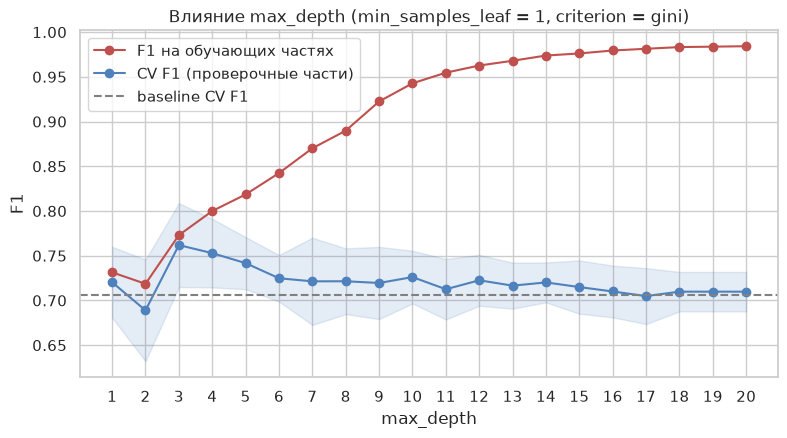

          1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20
train  0.731  0.719  0.773  0.800  0.819  0.842  0.870  0.890  0.922  0.943  0.955  0.963  0.968  0.974  0.976  0.979  0.981  0.983  0.984  0.984
CV     0.720  0.689  0.762  0.753  0.742  0.725  0.721  0.721  0.720  0.726  0.713  0.723  0.717  0.720  0.715  0.710  0.705  0.710  0.710  0.710
std    0.040  0.057  0.047  0.038  0.029  0.026  0.049  0.037  0.040  0.029  0.034  0.028  0.026  0.022  0.030  0.029  0.031  0.022  0.022  0.022


In [8]:
from sklearn.model_selection import validation_curve

depths = list(range(1, 21))
train_sc, val_sc = validation_curve(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    X_train, y_train, param_name="model__max_depth", param_range=depths,
    cv=cv, scoring="f1", n_jobs=-1
)

val_mean, val_std = val_sc.mean(axis=1), val_sc.std(axis=1)

plt.figure(figsize=(9, 4.5))
plt.plot(depths, train_sc.mean(axis=1), "o-", color="#c0504d", label="F1 на обучающих частях")
plt.plot(depths, val_mean, "o-", color="#4f81bd", label="CV F1 (проверочные части)")
plt.fill_between(depths, val_mean - val_std, val_mean + val_std, color="#4f81bd", alpha=0.15)
plt.axhline(cv_base["test_score"].mean(), color="gray", linestyle="--", label="baseline CV F1")
plt.xticks(depths)
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Влияние max_depth (min_samples_leaf = 1, criterion = gini)")
plt.legend()
plt.show()

print(pd.DataFrame({"train": train_sc.mean(axis=1), "CV": val_mean, "std": val_std},
                   index=depths).round(3).T.to_string())

### Вывод по влиянию max_depth

Кривые показывают F1 на обучающих частях (красная) и на проверочных (синяя) при глубине от 1 до 20, остальные параметры по умолчанию.

**Недообучение (глубина 1–2).** F1 на обучении всего 0.72–0.73, почти столько же, сколько на CV. Модель слишком простая: она не может хорошо описать даже обучающие данные. Глубина 1 — это одно разбиение, скорее всего по полу или титулу, то есть правило «женщины выжили, мужчины нет». На глубине 2 CV F1 даже падает до 0.689: дерево, видимо, отделяет группу женщин с низкой выживаемостью и начинает чаще ошибаться в ответе «погибла», поэтому падает Recall.

**Разумная сложность (глубина 3–5).** CV F1 максимален: 0.762 при глубине 3, 0.753 при 4 и 0.742 при 5. Разрыв между обучением и CV при глубине 3 всего 0.01. Разница между глубинами 3 и 4 (0.009) меньше разброса по folds, поэтому эти значения по качеству почти одинаковые. Глубина 3 лучшая, но ненамного.

**Переобучение (глубина 6 и больше).** F1 на обучении продолжает расти до 0.984, а CV F1 падает и держится около 0.71, на уровне baseline (0,706). Разрыв растёт до 0.274: дерево всё больше запоминает отдельных пассажиров, и это не помогает на новых данных. После глубины ~17 кривые почти не меняются, потому что дерево уже выросло и дальше не растёт.

Совпадает с ожиданием из раздела 5: с ростом глубины CV F1 сначала возрастает, а потом падает.

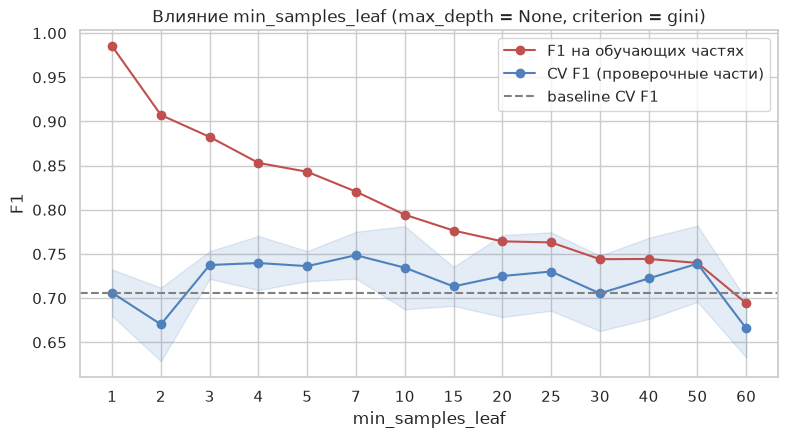

          1      2      3      4      5      7      10     15     20     25     30     40     50     60
train  0.985  0.907  0.882  0.853  0.843  0.821  0.794  0.777  0.764  0.763  0.744  0.744  0.740  0.694
CV     0.706  0.670  0.738  0.740  0.736  0.749  0.734  0.713  0.725  0.730  0.705  0.722  0.739  0.666
std    0.026  0.042  0.016  0.031  0.017  0.027  0.047  0.022  0.046  0.044  0.043  0.046  0.043  0.033


In [10]:
leaves = [1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60]
train_sc, val_sc = validation_curve(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    X_train, y_train, param_name="model__min_samples_leaf", param_range=leaves,
    cv=cv, scoring="f1", n_jobs=-1
)

val_mean, val_std = val_sc.mean(axis=1), val_sc.std(axis=1)
x = range(len(leaves))

plt.figure(figsize=(9, 4.5))
plt.plot(x, train_sc.mean(axis=1), "o-", color="#c0504d", label="F1 на обучающих частях")
plt.plot(x, val_mean, "o-", color="#4f81bd", label="CV F1 (проверочные части)")
plt.fill_between(x, val_mean - val_std, val_mean + val_std, color="#4f81bd", alpha=0.15)
plt.axhline(cv_base["test_score"].mean(), color="gray", linestyle="--", label="baseline CV F1")
plt.xticks(x, leaves)
plt.xlabel("min_samples_leaf")
plt.ylabel("F1")
plt.title("Влияние min_samples_leaf (max_depth = None, criterion = gini)")
plt.legend()
plt.show()

print(pd.DataFrame({"train": train_sc.mean(axis=1), "CV": val_mean, "std": val_std},
                   index=leaves).round(3).T.to_string())

### Вывод по влиянию min_samples_leaf

Здесь глубина не ограничена, меняется только минимальное число пассажиров в листе. Ось x «перевёрнута» по сравнению с `max_depth`: маленькое значение — сложное дерево, большое — простое.

**Переобучение (1–2).** При `min_samples_leaf` = 1 результат совпадает с baseline: F1 на обучении 0,985, CV 0,706. При 2 CV даже ниже (0,670). Листья могут содержать одного-двух пассажиров, и дерево их запоминает.

**Разумная сложность (3–25).** CV F1 от 0,713 до 0,749, лучший результат 0,749 при `min_samples_leaf` = 7. F1 на обучении снижается с 0,882 до 0,763: чем крупнее листья, тем меньше дерево может запомнить, и разрыв с CV сокращается.

**Недообучение (50 и больше).** При 50 F1 на обучении и на CV почти равны (0,740 и 0,739): модель уже не переобучается, это граница. При 60 обе линии падают (0,694 и 0,666): листья слишком крупные, и дерево не может выделить небольшие группы пассажиров.

Кривая неровная: например, при 30 CV F1 = 0,705, а при 50 0,739. Разница между соседними значениями меньше разброса по folds (~0,04), поэтому это скорее случайные колебания, чем реальная закономерность.

**Сравнение с `max_depth`.** Лучший CV F1 при ограничении только листа (0,749) ниже, чем при ограничении только глубины (0,762). Значит, на этих данных `max_depth` сильнее влияет на качество, и Grid Search не случайно выбрал `min_samples_leaf` = 1 при глубине 3: при такой глубине ограничение листа уже почти ничего не добавляет.

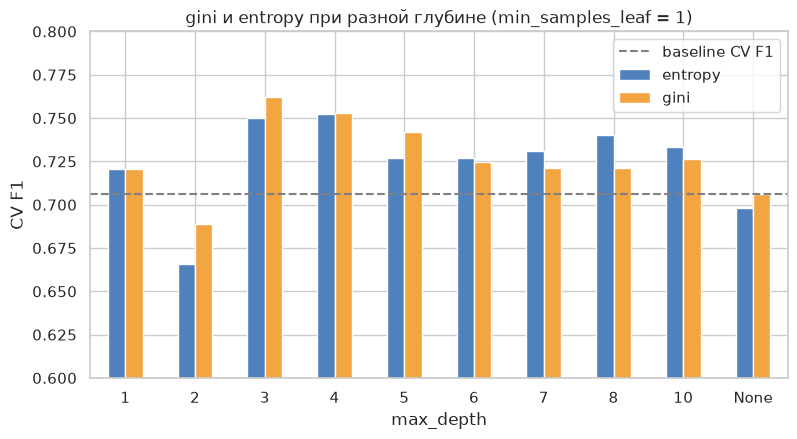

max_depth                  1      2      3      4      5      6      7      8     10   None
param_model__criterion                                                                     
entropy                 0.72  0.666  0.750  0.752  0.727  0.727  0.731  0.740  0.733  0.698
gini                    0.72  0.689  0.762  0.753  0.742  0.725  0.721  0.721  0.726  0.706

лучший CV F1 по всей сетке: {'entropy': 0.756, 'gini': 0.762}


In [11]:
res = pd.DataFrame(grid.cv_results_)
res = res[res["param_model__min_samples_leaf"] == 1].copy()
res["max_depth"] = res["param_model__max_depth"].apply(lambda d: "None" if d is None else str(d))

crit = res.pivot_table(index="max_depth", columns="param_model__criterion", values="mean_test_score")
crit = crit.reindex([str(d) for d in param_grid["model__max_depth"]])

crit.plot(kind="bar", figsize=(9, 4.5), color=["#4f81bd", "#f2a541"], rot=0)
plt.axhline(cv_base["test_score"].mean(), color="gray", linestyle="--", label="baseline CV F1")
plt.ylim(0.6, 0.8)
plt.xlabel("max_depth")
plt.ylabel("CV F1")
plt.title("gini и entropy при разной глубине (min_samples_leaf = 1)")
plt.legend()
plt.show()

print(crit.round(3).T.to_string())
best = pd.DataFrame(grid.cv_results_).groupby("param_model__criterion")["mean_test_score"].max()
print("\nлучший CV F1 по всей сетке:", best.round(3).to_dict())

### Вывод по влиянию criterion

Сравниваю `gini` и `entropy` при каждой глубине из сетки и `min_samples_leaf` = 1. Новых обучений не нужно: эти результаты уже посчитаны в Grid Search.

При одной и той же глубине критерии отличаются не больше чем на 0,023 (при глубине 2), а чаще примерно на 0,01. При глубине 1 результат совпадает (0,72): одно разбиение оба критерия выбирают одинаково.

Ни один критерий не лучше всегда: `gini` выше при глубине 2, 3, 5 и None, а `entropy` — при 6, 7, 8 и 10. Лучший результат по всей сетке: `gini` 0,762, `entropy` 0,756, разница 0,006, это намного меньше разброса по folds (~0,04). Значит, разница между критериями в основном случайная.

Для сравнения: при изменении `max_depth` CV F1 меняется от 0,666 до 0,762 (разница 0,096), то есть примерно в 4 раза сильнее, чем при смене критерия (не больше 0,023). Зависимость от глубины у обоих критериев одинаковая: недообучение при глубине 1–2, максимум при 3–4, переобучение дальше.

Это совпадает с ожиданием из раздела 5: `gini` и `entropy` почти одинаково оценивают разбиения. Из трёх выбранных параметров сильнее всего на качество влияет `max_depth`, слабее — `min_samples_leaf`, а `criterion` почти не влияет. Именно в такой ситуации Random Search эффективнее сетки: в Grid Search каждое сочетание глубины и листа проверялось дважды, с `gini` и с `entropy`, то есть половина из 120 комбинаций почти ничего не добавила, а разных значений глубины было проверено только 10.

## 9. Анализ устойчивости

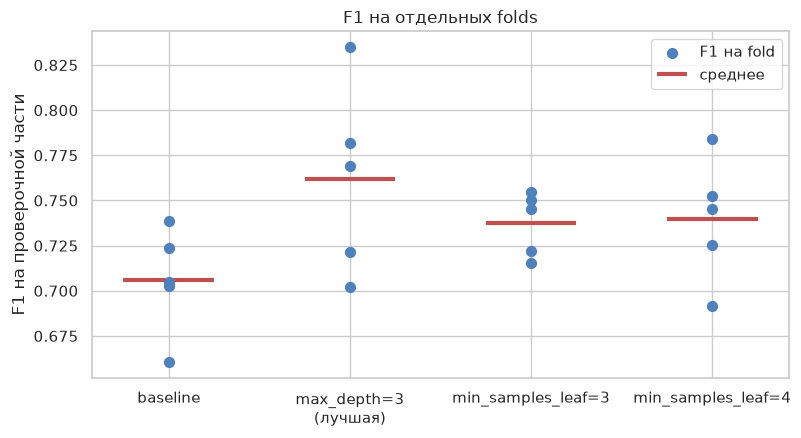

                      fold 1  fold 2  fold 3  fold 4  fold 5
baseline               0.739   0.661   0.705   0.703   0.724
max_depth=3 (лучшая)   0.782   0.702   0.835   0.721   0.769
min_samples_leaf=3     0.716   0.722   0.755   0.750   0.745
min_samples_leaf=4     0.745   0.692   0.725   0.752   0.784

                       mean    std    min    max  max - min
baseline              0.706  0.026  0.661  0.739      0.078
max_depth=3 (лучшая)  0.762  0.047  0.702  0.835      0.133
min_samples_leaf=3    0.738  0.016  0.716  0.755      0.039
min_samples_leaf=4    0.740  0.031  0.692  0.784      0.093


In [14]:
from sklearn.model_selection import cross_val_score

models = {
    "baseline": make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "max_depth=3\n(лучшая)": make_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
    "min_samples_leaf=3": make_pipeline(DecisionTreeClassifier(min_samples_leaf=3, random_state=RANDOM_STATE)),
    "min_samples_leaf=4": make_pipeline(DecisionTreeClassifier(min_samples_leaf=4, random_state=RANDOM_STATE)),
}

folds = pd.DataFrame(
    {name: cross_val_score(m, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1) for name, m in models.items()},
    index=[f"fold {i}" for i in range(1, 6)]
)

plt.figure(figsize=(9, 4.5))
for i, name in enumerate(folds.columns):
    plt.scatter([i] * 5, folds[name], color="#4f81bd", s=50, zorder=3, label="F1 на fold" if i == 0 else None)
    plt.hlines(folds[name].mean(), i - 0.25, i + 0.25, color="#c0504d", linewidth=3, label="среднее" if i == 0 else None)
plt.xticks(range(len(folds.columns)), folds.columns)
plt.ylabel("F1 на проверочной части")
plt.title("F1 на отдельных folds")
plt.legend()
plt.show()

summary = pd.DataFrame({
    "mean": folds.mean(), "std": folds.std(ddof=0),
    "min": folds.min(), "max": folds.max(),
})
summary["max - min"] = summary["max"] - summary["min"]
print(folds.round(3).T.rename(index=lambda s: s.replace("\n", " ")).to_string())
print()
print(summary.round(3).rename(index=lambda s: s.replace("\n", " ")).to_string())

### Вывод по устойчивости

Среднее CV F1 не показывает, насколько результат зависит от того, какие пассажиры попали в проверочную часть, поэтому смотрю на F1 по отдельным folds и на разброс.

**Лучшая модель и baseline.** У дерева глубины 3 среднее выше, но и разброс больше (0.133 ghjnbd 0.078). При этом оно лучше baseline на 5 folds из 5, поэтому улучшение от подбора не случайное: оно есть при любом составе проверочной части.

**Трудный fold.** На fold 2 F1 ниже всего у трёх моделей из четырёх. Значит, дело не в модели, а в данных этого fold: туда попало больше пассажиров, чей исход трудно предсказать по признакам.

**Одинаковое среднее, разная устойчивость.** У `min_samples_leaf` = 3 и 4 средние почти равны, а размах у второй в 2.4 раза больше. В каждом fold всего ~55 выживших, и ошибка на нескольких пассажирах заметно меняет F1. Если листья держатся на немногих пассажирах, модель сильнее зависит от того, кто попал в обучающую часть. При равном среднем лучше модель с меньшим разбросом: её качество на новых данных предсказуемее.

**Что это значит для выбора.** Разница в среднем между глубиной 3 и min_samples_leaf = 3 (0,024) меньше std лучшей модели (0,047), поэтому по CV нельзя уверенно сказать, что глубина 3 лучше всех. Выбираю её, потому что она лучшая по среднему и стабильно лучше baseline, но на test результат может отличаться от CV F1 (0,762) в пределах ~0,05.

## 10. Финальная модель

               CV F1  Test F1  Test − CV
baseline       0.706    0.725      0.019
Grid Search    0.762    0.769      0.007
Random Search  0.762    0.769      0.007


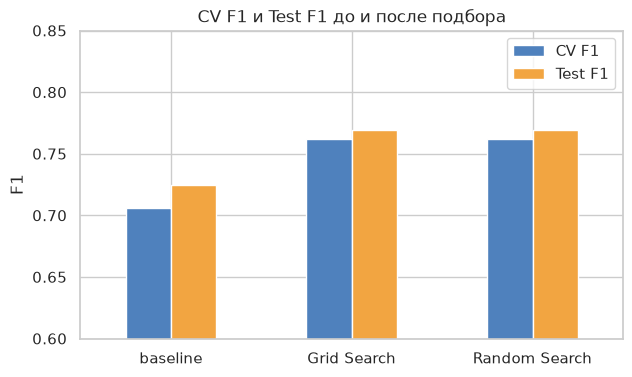

In [15]:
from sklearn.metrics import f1_score

baseline.fit(X_train, y_train)

final = {
    "baseline": (baseline, cv_base["test_score"].mean()),
    "Grid Search": (grid.best_estimator_, grid.best_score_),
    "Random Search": (rand.best_estimator_, rand.best_score_),
}

table = pd.DataFrame({
    name: {"CV F1": cv, "Test F1": f1_score(y_test, model.predict(X_test))}
    for name, (model, cv) in final.items()
}).T
table["Test − CV"] = table["Test F1"] - table["CV F1"]
print(table.round(3).to_string())

table[["CV F1", "Test F1"]].plot(kind="bar", figsize=(7, 4), rot=0, color=["#4f81bd", "#f2a541"])
plt.ylim(0.6, 0.85)
plt.ylabel("F1")
plt.title("CV F1 и Test F1 до и после подбора")
plt.show()

### Вывод по финальной модели

Финальная модель — дерево с `max_depth` = 3, `min_samples_leaf` = 1, `criterion` = gini, обученное на всём train. Grid Search и Random Search нашли одни и те же параметры, поэтому их результаты совпадают. Test использован один раз, после того как все параметры были выбраны по CV.

**Насколько улучшилось качество.** Подбор поднял CV F1 на 0,056 (с 0,706 до 0,762), а Test F1 на 0,044 (с 0,725 до 0,769). Baseline на test получил то же значение, что в ЛР2, значит, эксперимент воспроизводится.

**Совпадает ли улучшение на CV и на test.** Почти: на test оно меньше, чем на CV, но разница небольшая (0,012) и меньше разброса по folds (~0,05). У всех моделей Test F1 немного выше CV F1.

**Чем это объяснить.**
- CV F1 лучшей модели немного пассажиров: из 120 комбинаций выбрана та, которой на этих folds повезло больше всех. На test, который в выборе не участвовал, это «везение» частично пропадает, поэтому улучшение на test меньше.
- Test выше CV, потому что финальная модель обучена на 712 пассажирах, а модели в CV — на ~570, и потому что test маленький (179 пассажиров), так что отклонение на ~0,01–0,02 — это случайность.

## Итог

Для подбора гиперпараметров взяла задачу из ЛР2 (Titanic) и дерево решений. Baseline — то же дерево с параметрами по умолчанию: оно сильно переобучается (F1 на обучающих частях 0,985, CV F1 0,706).

Подбирала три гиперпараметра: `max_depth`, `min_samples_leaf` и `criterion`. Все решения принимала по кросс-валидации на train (`StratifiedKFold`, 5 folds), test использовала только один раз, для финальной проверки.

Главные выводы:
- **Подбор помог.** Лучшие параметры: `max_depth` = 3, `min_samples_leaf` = 1, `criterion` = gini. CV F1 вырос с 0,706 до 0,762, Test F1 — с 0,725 до 0,769. Улучшение на test чуть меньше, чем на CV, потому что CV F1 лучшей модели немного завышен выбором из 120 комбинаций.
- **Grid Search и Random Search** нашли одни и те же параметры за одинаковое время. Random Search при этом проверил только 5% своего пространства. На маленькой задаче оба способа подходят, а при большом числе параметров случайный поиск выгоднее.
- **Важнее всего `max_depth`.** При глубине 1–2 дерево недообучается, при 3–5 качество лучшее, дальше оно переобучается и опускается до уровня baseline. `min_samples_leaf` влияет слабее (лучший CV F1 0,749), а `criterion` почти не влияет: разница между `gini` и `entropy` меньше разброса по folds.
- **Устойчивость.** Лучшая модель обгоняет baseline на 5 folds из 5, поэтому улучшение не случайное. Но её F1 по folds меняется от 0,702 до 0,835, так что разница с близкими по качеству вариантами (например, `min_samples_leaf` = 3) в пределах шума.

Главный урок: дерево без ограничений запоминает обучающих пассажиров, и простое ограничение сложности (глубина 3, не больше 8 листьев) даёт модель, которая лучше работает на новых данных.